# INTERPRETABILIDAD DE LOS MODELOS

In [1]:
# Librerias 

import pandas as pd
import joblib
import matplotlib.pyplot as plt
import shap

c:\Users\aldyv\OneDrive\Dokumenter\BACHELOR DATA SCIENCE\TFG\TFG MATERIAL\TFG DATASET\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# CARGAR LOS DATOS 
X_test_diab = pd.read_csv("../data/processed/X_test_diab_df.csv")
X_train_diab = pd.read_csv("../data/processed/X_train_diab_df.csv")

In [3]:
# ======================
# 1. CARGAR LOS MODELOS 
# ======================

reg_log_diab = joblib.load("../models/reg_log_diab.joblib")
xgb_diab_opt = joblib.load("../models/xgb_diab_optimizado.joblib")

print("Modelos cargados correctamente")

Modelos cargados correctamente


Background dataset has 16695 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=16695 when initializing the masker.


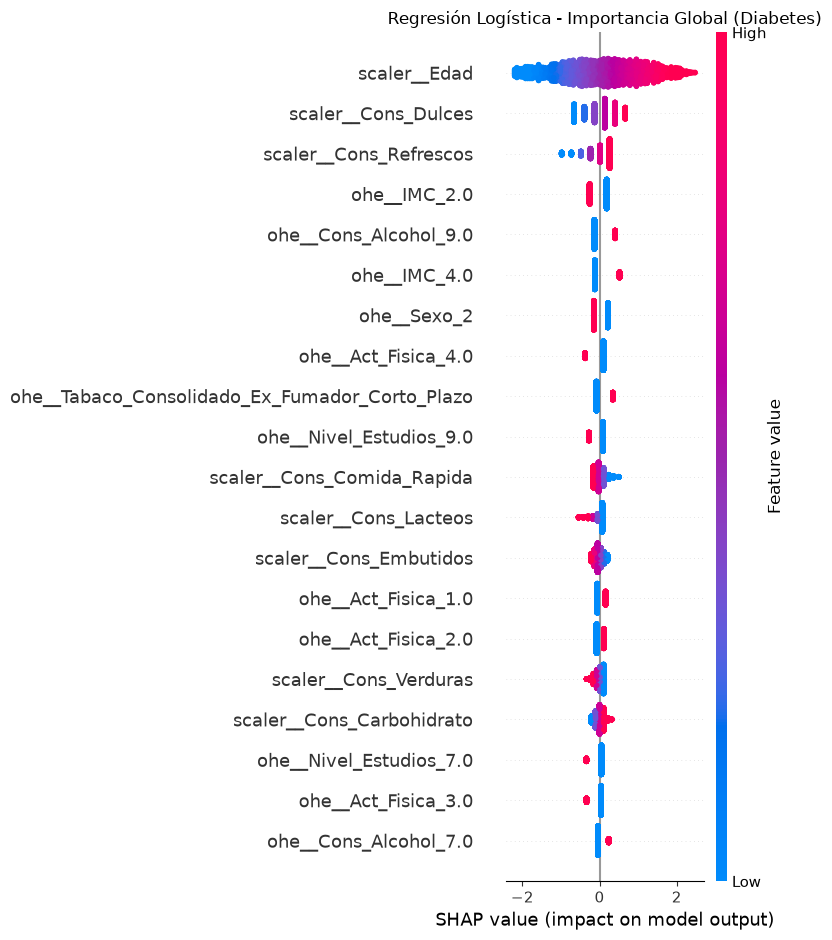

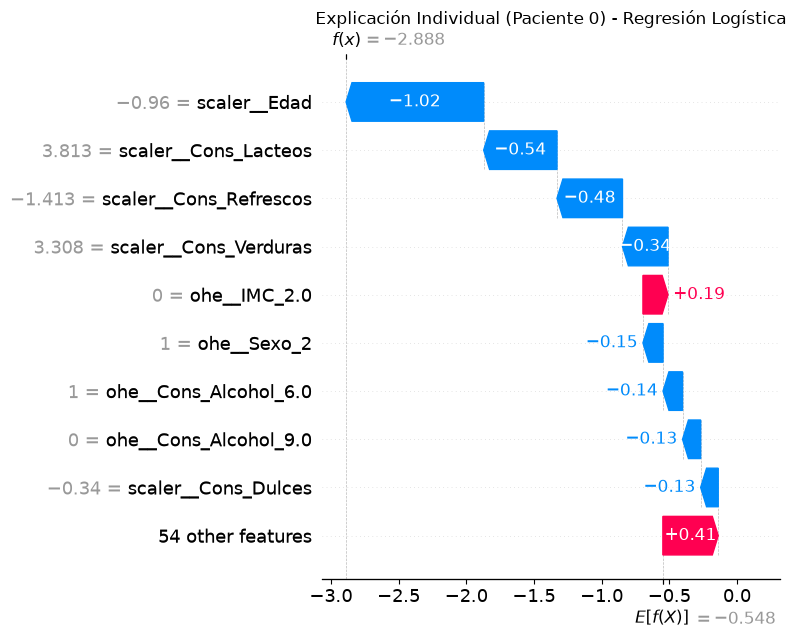

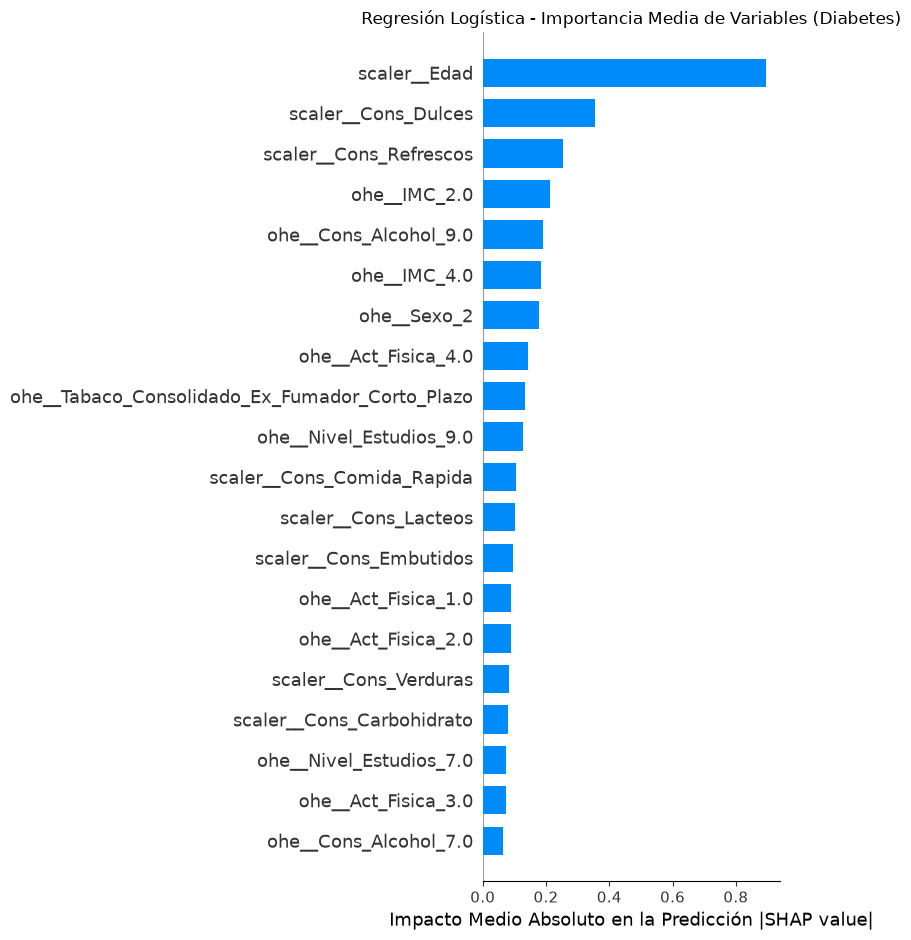

In [4]:
# ==========================================
# 2. SHAP PARA REGRESIÓN LOGÍSTICA
# ==========================================


shap_rl = shap.Explainer(
    reg_log_diab, 
    X_train_diab, 
)
shap_values_rl = shap_rl(X_test_diab)

# Importancia Global (Summary Plot)
plt.figure(figsize=(10, 6))
plt.title("Regresión Logística - Importancia Global (Diabetes)", fontsize=12)
shap.summary_plot(shap_values_rl, X_test_diab, show=False)
plt.tight_layout()
plt.savefig("../reports/figures/results/shap_imp_global_reg_log_diab.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

# Caso Individual (Waterfall - Paciente 0)
plt.figure(figsize=(8, 5))
shap.plots.waterfall(shap_values_rl[0], show=False)
plt.title("Explicación Individual (Paciente 0) - Regresión Logística", fontsize=12)
plt.tight_layout()
plt.savefig("../reports/figures/results/shap_caso_individual_reg_log_diab", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

# ==========================================
# BAR PLOT DE IMPORTANCIA GLOBAL (SHAP)
# ==========================================

plt.figure(figsize=(10, 6))
plt.title("Regresión Logística - Importancia Media de Variables (Diabetes)", fontsize=12)
shap.summary_plot(shap_values_rl, X_test_diab, plot_type="bar", show=False)
plt.xlabel("Impacto Medio Absoluto en la Predicción |SHAP value|")
plt.tight_layout()
plt.savefig("../reports/figures/results/shap_impacto_medio_absoluto_reg_log_diab", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

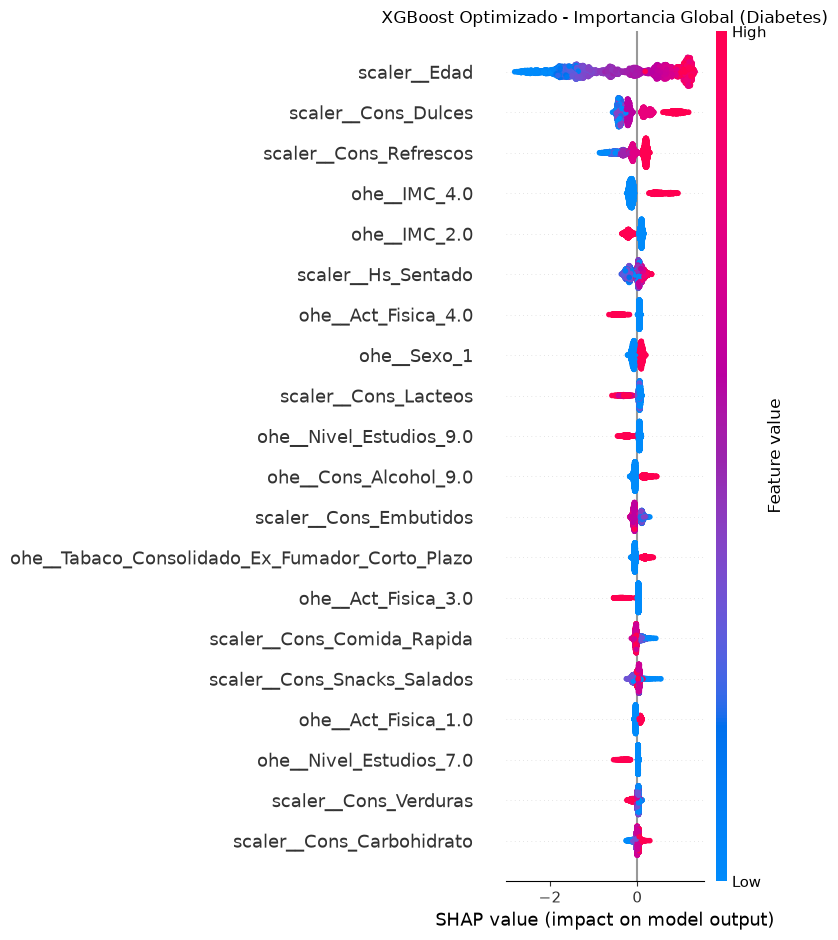

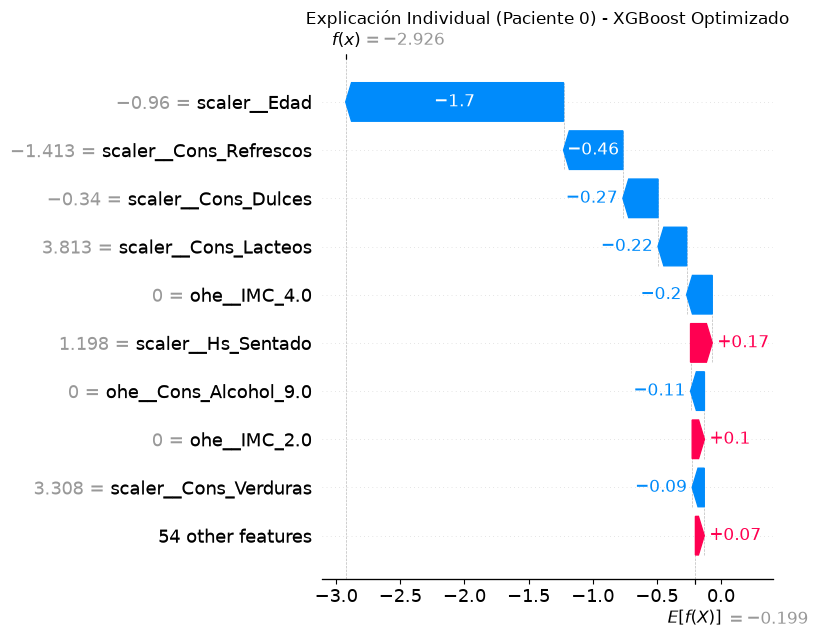

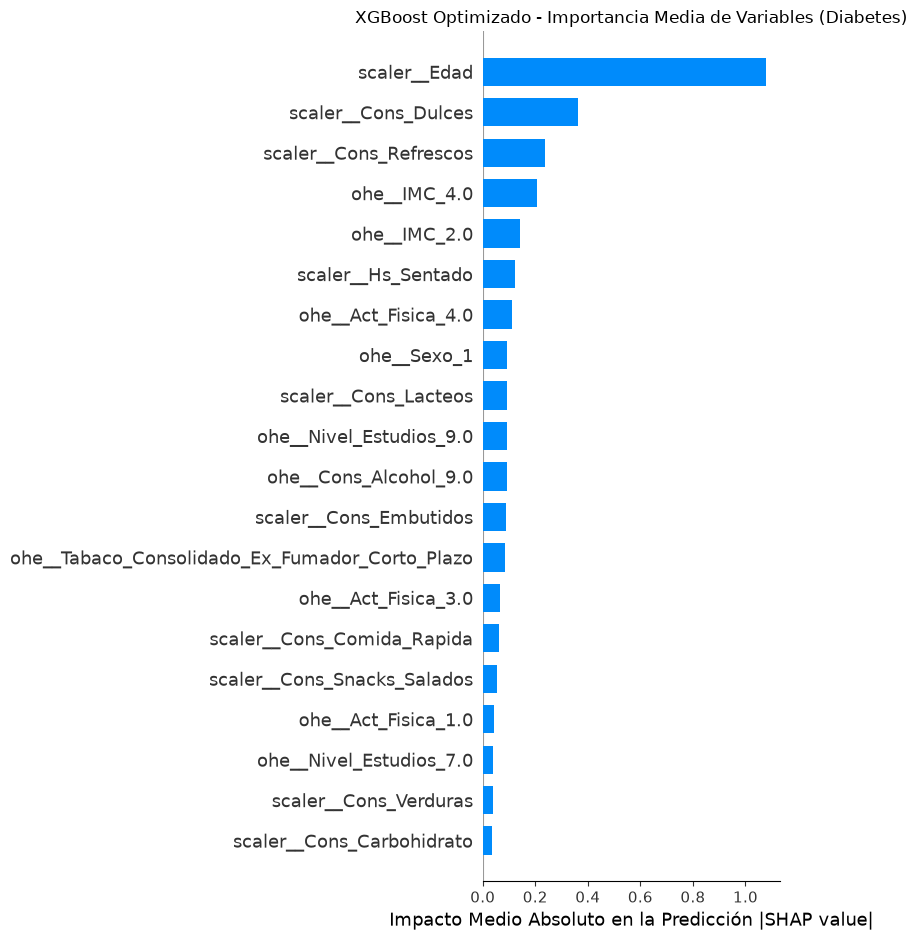

In [5]:
# ==========================================
# 3. SHAP PARA XGBOOST OPTIMIZADO
# ==========================================

shap_xgb = shap.TreeExplainer(xgb_diab_opt)
shap_values_xgb = shap_xgb(X_test_diab)

# Importancia Global (Summary Plot)
plt.figure(figsize=(10, 6))
plt.title("XGBoost Optimizado - Importancia Global (Diabetes)", fontsize=12)
shap.summary_plot(shap_values_xgb, X_test_diab, show=False)
plt.tight_layout()
plt.savefig("../reports/figures/results/shap_imp_global_xbg_diab.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

# Caso Individual (Waterfall - Paciente 0)
plt.figure(figsize=(8, 5))
shap.plots.waterfall(shap_values_xgb[0], show=False)
plt.title("Explicación Individual (Paciente 0) - XGBoost Optimizado", fontsize=12)
plt.tight_layout()
plt.savefig("../reports/figures/results/shap_explicación_individual_xgb_diab.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

# ==========================================
# BAR PLOT DE IMPORTANCIA GLOBAL (SHAP)
# ==========================================

plt.figure(figsize=(10, 6))
plt.title("XGBoost Optimizado - Importancia Media de Variables (Diabetes)", fontsize=12)
shap.summary_plot(shap_values_xgb, X_test_diab, plot_type="bar", show=False)
plt.xlabel("Impacto Medio Absoluto en la Predicción |SHAP value|")
plt.tight_layout()
plt.savefig("../reports/figures/results/shap_impacto_medio_absoluto_xgb_diab.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()